Test de R 

In [38]:
library(Seurat)
library(ggplot2)
library(dplyr)
library(tibble)
library(purrr)
library(patchwork)
library(rlang)
library(ggrepel)
library(tidyr)
library(tibble)
library(sctransform)

In [5]:
# read RDS file
path  <- "data/RDS/GeneFull_raw_unique_mult_with_metadata_grouped_filtered_100UMI_3c_SeuratV5.rds"
seurat_obj <- readRDS(path)

In [6]:
seurat_obj
# view the Seurat object


An object of class Seurat 
5500 features across 2988 samples within 1 assay 
Active assay: RNA (5500 features, 0 variable features)
 1 layer present: counts

In [7]:
cat("Available assays:\n")
print(Assays(seurat_obj))

cat("\nAvailable layers:\n")
print(Layers(seurat_obj))

#choose the assay to work with
GetAssay(seurat_obj, assay = "RNA")


Available assays:
[1] "RNA"

Available layers:
[1] "counts"


Assay (v5) data with 5500 features for 2988 cells
First 10 features:
 recC, recB, recD, QLH64-00045, QLH64-00050, QLH64-00055, QLH64-00060,
QLH64-00070, QLH64-00075, QLH64-00080 
Layers:
 counts 

In [8]:
cat("\nGene annotation information:\n")
cat("Number of features in Seurat object:", nrow(seurat_obj), "\n")
cat("Number of cells in Seurat object:", ncol(seurat_obj), "\n")


Gene annotation information:
Number of features in Seurat object: 5500 
Number of cells in Seurat object: 2988 


In [9]:
# Display available columns
cat("\nAvailable columns in metadata of cells (or barcodes because there are not filtered for the moment)):\n")
colnames(seurat_obj@meta.data)
head(seurat_obj)


Available columns in metadata of cells (or barcodes because there are not filtered for the moment)):


[1] "orig.ident"                  "nCount_RNA"                 
 [3] "nFeature_RNA"                "barcode"                    
 [5] "Well_loc_rd1"                "Well_loc_rd2"               
 [7] "Well_loc_rd3"                "CultureMedium"              
 [9] "RepBio"                      "OD"                         
[11] "RepTech"                     "ODt"                        
[13] "OD_theoric"                  "OD_measured"                
[15] "Extracted_Sequence_rd1"      "Group"                      
[17] "n_genes"                     "RepTech_suffix"             
[19] "RepBio_suffix"               "group"                      
[21] "n_genes_by_counts"           "log1p_n_genes_by_counts"    
[23] "total_counts"                "log1p_total_counts"         
[25] "pct_counts_in_top_50_genes"  "pct_counts_in_top_100_genes"
[27] "pct_counts_in_top_200_genes" "pct_counts_in_top_500_genes"

,orig.ident,nCount_RNA,nFeature_RNA,barcode,Well_loc_rd1,Well_loc_rd2,Well_loc_rd3,CultureMedium,RepBio,OD,...,RepBio_suffix,group,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,pct_counts_in_top_500_genes
,<fct>,<dbl>,<int>,<chr>,<fct>,<fct>,<fct>,<fct>,<fct>,<fct>,...,<fct>,<fct>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
GATGAATC_AATGTTGC_CTGCTTTG,GATGAATC,1673,850,GATGAATC_AATGTTGC_CTGCTTTG,E1,G1,H11,M9F,M9F_A,M9F_A_OD1,...,A,M9F_sampling_t1,850,6.746412,1673,7.422971,28.81052,41.12373,56.18649,79.07950
ACTATGCA_GAGCTGAA_CTGCTTTG,ACTATGCA,1542,852,ACTATGCA_GAGCTGAA_CTGCTTTG,E1,D12,B11,M9F,M9F_A,M9F_A_OD1,...,A,M9F_sampling_t1,852,6.748760,1542,7.341484,27.04280,39.75357,54.86381,77.17250
TATCAGCA_GACTAGTA_CTGCTTTG,TATCAGCA,1499,828,TATCAGCA_GACTAGTA_CTGCTTTG,E1,C7,F1,M9F,M9F_A,M9F_A_OD1,...,A,M9F_sampling_t1,828,6.720220,1499,7.313220,27.95197,39.82655,54.63642,78.11875
ACCACTGT_ATCCTGTA_CTGCTTTG,ACCACTGT,1466,814,ACCACTGT_ATCCTGTA_CTGCTTTG,E1,C4,A5,M9F,M9F_A,M9F_A_OD1,...,A,M9F_sampling_t1,814,6.703188,1466,7.290975,26.60300,38.26739,53.75171,78.58117
CAAGACTA_AACAACCA_CTGCTTTG,CAAGACTA,1388,779,CAAGACTA_AACAACCA_CTGCTTTG,E1,B1,D11,M9F,M9F_A,M9F_A_OD1,...,A,M9F_sampling_t1,779,6.659294,1388,7.236339,27.66571,40.20173,56.12392,79.89914
TCTTCACA_AATCCGTC_CTGCTTTG,TCTTCACA,1289,724,TCTTCACA_AATCCGTC_CTGCTTTG,E1,F12,F3,M9F,M9F_A,M9F_A_OD1,...,A,M9F_sampling_t1,724,6.586172,1289,7.162397,29.16990,42.04810,57.95190,82.62219
CGCTGATC_AACGTGAT_CTGCTTTG,CGCTGATC,1292,745,CGCTGATC_AACGTGAT_CTGCTTTG,E1,A1,A9,M9F,M9F_A,M9F_A_OD1,...,A,M9F_sampling_t1,745,6.614726,1292,7.164720,27.70898,40.32508,56.65635,81.03715
AGAGTCAA_CCTCCTGA_CTGCTTTG,AGAGTCAA,1274,717,AGAGTCAA_CCTCCTGA_CTGCTTTG,E1,D3,B12,M9F,M9F_A,M9F_A_OD1,...,A,M9F_sampling_t1,717,6.576470,1274,7.150701,27.94349,40.50235,57.06436,82.96703
TTCACGCA_TGAAGAGA_CTGCTTTG,TTCACGCA,1306,723,TTCACGCA_TGAAGAGA_CTGCTTTG,E1,F4,F8,M9F,M9F_A,M9F_A_OD1,...,A,M9F_sampling_t1,723,6.584791,1306,7.175490,28.86677,41.42420,57.35069,82.92496


In [26]:
seurat_obj@meta.data %>%
    summarise(
        CultureMedium = n_distinct(CultureMedium),
        RepBio = n_distinct(RepBio),
        OD = n_distinct(OD),
        RepTech = n_distinct(RepTech), 
        ODt = n_distinct(ODt)
    ) %>%
    pivot_longer(everything(), names_to = "Column", values_to = "Unique_Values")

Column,Unique_Values
<chr>,<int>
CultureMedium,2
RepBio,6
OD,18
RepTech,45
ODt,3


C'est uniquement une coincidence s'il ne reste que 45 RepTech apres le filtrage  (sur les 90 initialement présents)

In [23]:
# view OD name
seurat_obj@meta.data %>%
    select(OD) %>%
    unique()

,OD
,<fct>
GATGAATC_AATGTTGC_CTGCTTTG,M9F_A_OD1
CCTAATCC_CCATCCTC_TCGTTTCG,M9F_A_OD2
GCTAACGA_ACCTCCAA_TAATACGC,M9F_A_OD3
ACATTGGC_TCTTCACA_GTGGGTTC,M9F_B_OD1
CACCTTAC_CCAGTTCA_ACGGACTC,M9F_B_OD2
ATCCTGTA_AGCAGGAA_ACCGTACG,M9F_B_OD3
CCTAATCC_TCCGTCTA_GGGTAGCG,M9F_C_OD1
TCTTCACA_AGTCACTA_GCAAATTC,M9F_C_OD2
CCTCCTGA_CATACCAA_TATAGTCG,M9F_C_OD3


In [27]:
# cherche le nombre de valeurs uniques dans chaque colonne du tableau 
seurat_obj@meta.data %>%
    summarise_all(n_distinct) %>%
    pivot_longer(everything(), names_to = "Column", values_to = "Unique_Values")

Column,Unique_Values
<chr>,<int>
orig.ident,95
nCount_RNA,1044
nFeature_RNA,713
barcode,2988
Well_loc_rd1,45
Well_loc_rd2,95
Well_loc_rd3,95
CultureMedium,2
RepBio,6


In [25]:
# affiche les valeurs uniques de RepTech
seurat_obj@meta.data %>%
    select(RepTech) %>%
    unique() %>%
    arrange(RepTech)

,RepTech
,<fct>
GATGAATC_AATGTTGC_CTGCTTTG,M9F_A_OD1_1
TGGTGGTA_AGATGTAC_CTACCCTA,M9F_A_OD1_4
AAGAGATC_AACGTGAT_TACGGTTA,M9F_A_OD1_5
CCTAATCC_CCATCCTC_TCGTTTCG,M9F_A_OD2_2
GATGAATC_ATCATTCC_TGCGATCG,M9F_A_OD2_4
GCTAACGA_ACCTCCAA_TAATACGC,M9F_A_OD3_3
TTCACGCA_AACCGAGA_TTCATCGC,M9F_B_OD1_3
ACATTGGC_TCTTCACA_GTGGGTTC,M9F_B_OD1_4
CACCTTAC_CCAGTTCA_ACGGACTC,M9F_B_OD2_1


In [30]:
seurat_obj@meta.data %>%
    group_by(CultureMedium) %>%
    summarise(n_cells = n()) |> 
    arrange(desc(n_cells))

# nombre de valeur dans la colonne "CultureMedium"
cat("\nNumber of unique values in 'CultureMedium' column:\n")
unique_CultureMediums <- unique(seurat_obj$CultureMedium)
cat(length(unique_CultureMediums), "\n")
cat("Unique conditions:\n")
print(unique_CultureMediums)

CultureMedium,n_cells
<fct>,<int>
M9,1494
M9F,1494



Number of unique values in 'CultureMedium' column:
2 
Unique conditions:
[1] M9F M9 
Levels: M9 M9F


In [31]:

# Display available columns
cat("\nAvailable columns in metadata genes (features):\n")
# see the genes info layer metadata
colnames(seurat_obj[["RNA"]]@meta.data)
# colnames(GetAssay(seurat_obj, assay = "RNA")@meta.data) # fait pareil

head(seurat_obj@assays$RNA@meta.data)


Available columns in metadata genes (features):


[1] "gene_id"                         "final_gene_name"                
 [3] "symbol_renamed"                  "Gene Type"                      
 [5] "Name"                            "Protein accession"              
 [7] "symbol_old"                      "locus_tag_old"                  
 [9] "n_cells_by_counts"               "mean_counts"                    
[11] "log1p_mean_counts"               "pct_dropout_by_counts"          
[13] "total_counts"                    "log1p_total_counts"             
[15] "n_cells"                         "gene_pass_union_OD_5pct"        
[17] "gene_pass_intersection_OD_5pct"  "gene_pass_union_OD_10pct"       
[19] "gene_pass_intersection_OD_10pct" "gene_pass_union_OD_15pct"       
[21] "gene_pass_intersection_OD_15pct"

,gene_id,final_gene_name,symbol_renamed,Gene Type,Name,Protein accession,symbol_old,locus_tag_old,n_cells_by_counts,mean_counts,...,pct_dropout_by_counts,total_counts,log1p_total_counts,n_cells,gene_pass_union_OD_5pct,gene_pass_intersection_OD_5pct,gene_pass_union_OD_10pct,gene_pass_intersection_OD_10pct,gene_pass_union_OD_15pct,gene_pass_intersection_OD_15pct
,<chr>,<chr>,<lgl>,<fct>,<fct>,<fct>,<fct>,<chr>,<int>,<dbl>,...,<dbl>,<int>,<dbl>,<int>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>
recC,QLH64-00030,recC,FALSE,protein-coding,exodeoxyribonuclease V subunit gamma,WHS54405.1,recC,QLH64_00030,154,0.05287818,...,94.84605,158,5.068904,154,TRUE,FALSE,TRUE,FALSE,FALSE,FALSE
recB,QLH64-00035,recB,FALSE,protein-coding,exodeoxyribonuclease V subunit beta,WHS54406.1,recB,QLH64_00035,114,0.03882195,...,96.18474,116,4.762174,114,TRUE,FALSE,TRUE,FALSE,FALSE,FALSE
recD,QLH64-00040,recD,FALSE,protein-coding,exodeoxyribonuclease V subunit alpha,WHS54407.1,recD,QLH64_00040,107,0.03714859,...,96.41901,111,4.718499,107,TRUE,FALSE,TRUE,FALSE,FALSE,FALSE
QLH64-00045,QLH64-00045,QLH64-00045,TRUE,protein-coding,YfiR family protein,WHS54408.1,NA,QLH64_00045,55,0.01874163,...,98.15930,56,4.043051,55,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE
QLH64-00050,QLH64-00050,QLH64-00050,TRUE,protein-coding,diguanylate cyclase,WHS54409.1,NA,QLH64_00050,45,0.01539491,...,98.49398,46,3.850148,45,TRUE,FALSE,FALSE,FALSE,FALSE,FALSE
QLH64-00055,QLH64-00055,QLH64-00055,TRUE,protein-coding,OmpA family protein,WHS57090.1,NA,QLH64_00055,48,0.01639893,...,98.39357,49,3.912023,48,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE


In [33]:
generate_qc_plots <- function(
    seurat_obj,
    subtitle,
    group.by = "OD",
    split.by = NULL,
    show.points = FALSE,
    color.by = NULL,
    color.mapping = NULL
) {
    if (missing(subtitle) || is.null(subtitle) || subtitle == "") {
        stop("Le paramètre 'subtitle' est obligatoire.")
    }

    pt.size.val <- ifelse(show.points, 1, 0)

    # Génération du mapping de couleurs si color.by est défini
    if (!is.null(color.by)) {
        meta_df <- seurat_obj@meta.data %>%
            dplyr::select(all_of(group.by), all_of(color.by)) %>%
            dplyr::distinct()

        # Si aucun mapping fourni, on crée une palette auto
        if (is.null(color.mapping)) {
            unique_groups <- unique(meta_df[[color.by]])
            palette_fun <- scales::hue_pal()(length(unique_groups))
            color.mapping <- setNames(palette_fun, unique_groups)
        }

        meta_df$color <- color.mapping[meta_df[[color.by]]]
        named_colors <- setNames(meta_df$color, meta_df[[group.by]])
    } else if (!is.null(color.mapping)) {
        # Si pas de color.by, on suppose que color.mapping est pour group.by
        named_colors <- color.mapping
    } else {
        named_colors <- NULL
    }

    # p1
    p1 <- VlnPlot(seurat_obj,
        features = "nFeature_RNA",
        ncol = 1,
        pt.size = pt.size.val,
        group.by = group.by,
        raster = TRUE,
        layer = "counts"
    ) +
        labs(
            title = "Number of genes per cell",
            subtitle = subtitle,
            x = group.by,
            y = "Number of genes (nFeature_RNA)"
        ) +
        scale_y_continuous(limits = c(0, NA))

    if (!is.null(named_colors)) {
        p1 <- p1 + scale_fill_manual(values = named_colors)
    }

    # p2
    p2 <- VlnPlot(seurat_obj,
        features = "nCount_RNA",
        ncol = 1,
        pt.size = pt.size.val,
        group.by = group.by,
        raster = TRUE,
        layer = "counts"
    ) +
        labs(
            title = "Number of counts per cell",
            subtitle = subtitle,
            x = group.by,
            y = "Number of counts (nCount_RNA)"
        ) +
        scale_y_continuous(limits = c(0, NA))

    if (!is.null(named_colors)) {
        p2 <- p2 + scale_fill_manual(values = named_colors)
    }

    # p3 : scatter
    p3 <- FeatureScatter(seurat_obj,
        feature1 = "nCount_RNA",
        feature2 = "nFeature_RNA",
        group.by = group.by,
        raster = TRUE,
        split.by = split.by
    )

    if (!is.null(named_colors)) {
        p3 <- p3 + scale_color_manual(values = named_colors)
    }

    # p4 : ridgeplot
    cell_counts_df <- seurat_obj@meta.data %>%
        group_by(across(all_of(group.by))) %>%
        summarise(n = n(), .groups = "drop")

    cell_counts_label <- paste0(cell_counts_df[[group.by]], " (n=", cell_counts_df$n, ")", collapse = "\n")

    p4 <- RidgePlot(seurat_obj,
        features = "nCount_RNA",
        group.by = group.by,
        log = TRUE
    ) +
        theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
        labs(
            title = paste("Distribution of UMIs per cell across conditions\n", cell_counts_label),
            subtitle = subtitle,
            x = "Number of UMIs per cell (log scale)",
            y = "Density"
        )

    if (!is.null(named_colors)) {
        p4 <- p4 + scale_fill_manual(values = named_colors)
    }

    combined_p1_p2 <- p1 / p2

    return(list(
        p1 = p1,
        p2 = p2,
        combined_p1_p2 = combined_p1_p2,
        scatter_p3 = p3,
        ridge_p4 = p4
    ))
}

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for x is already present.
Adding another scale for x, which will replace the existing scale.


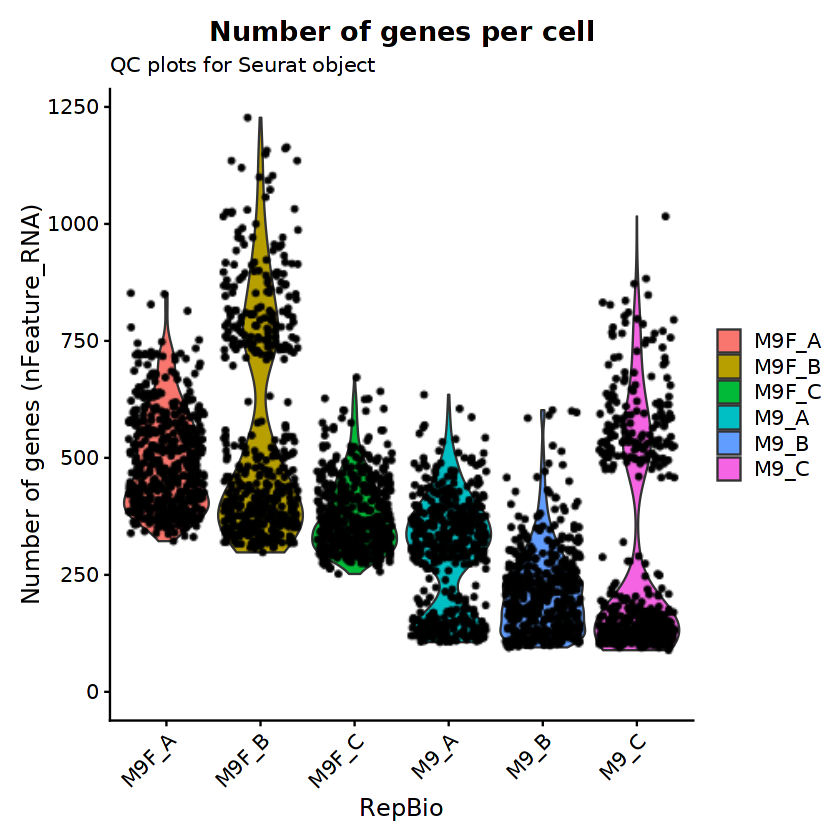

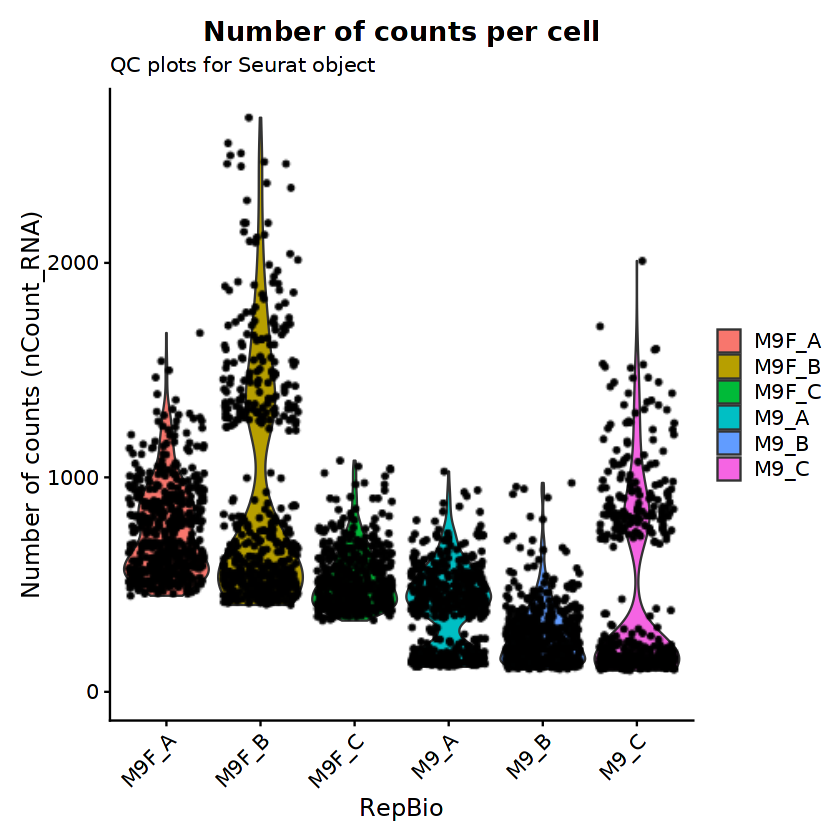

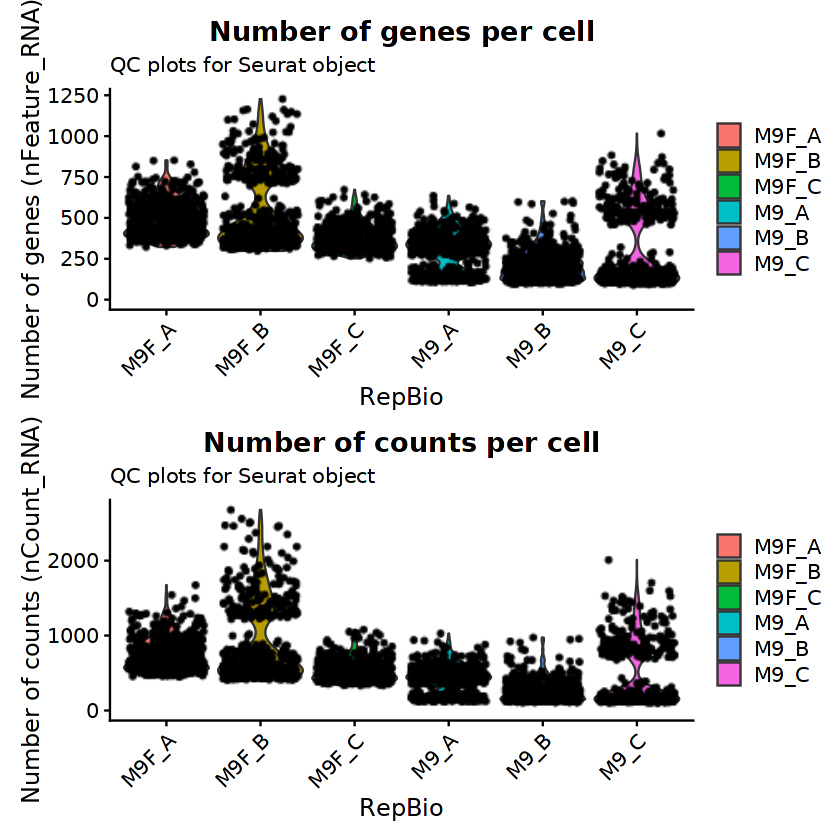

Picking joint bandwidth of 0.0557



$p1

$p2

$combined_p1_p2

$scatter_p3

$ridge_p4


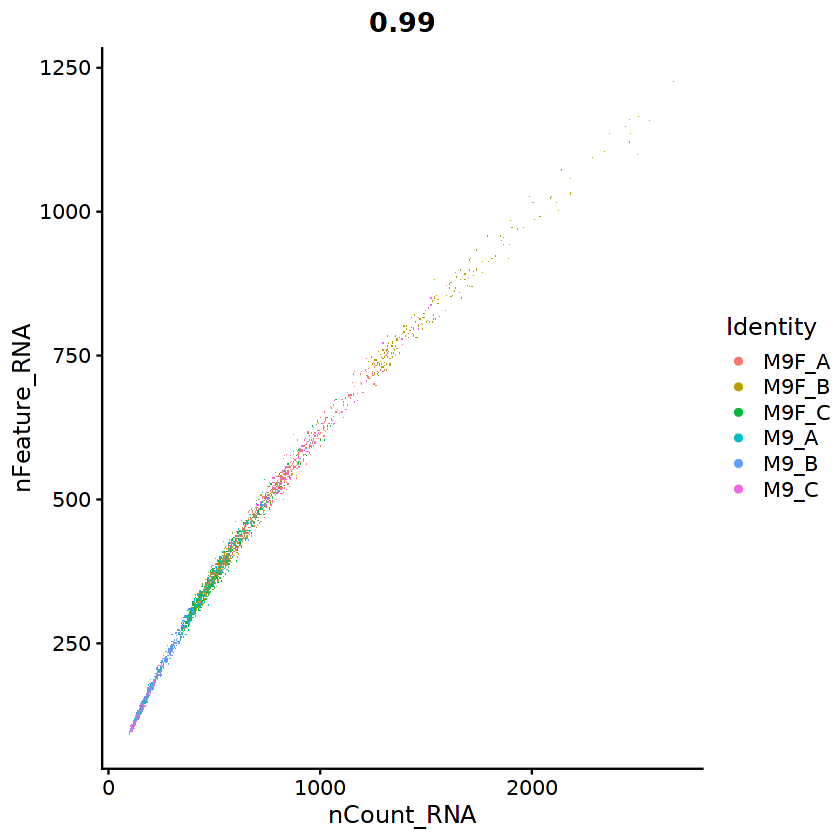

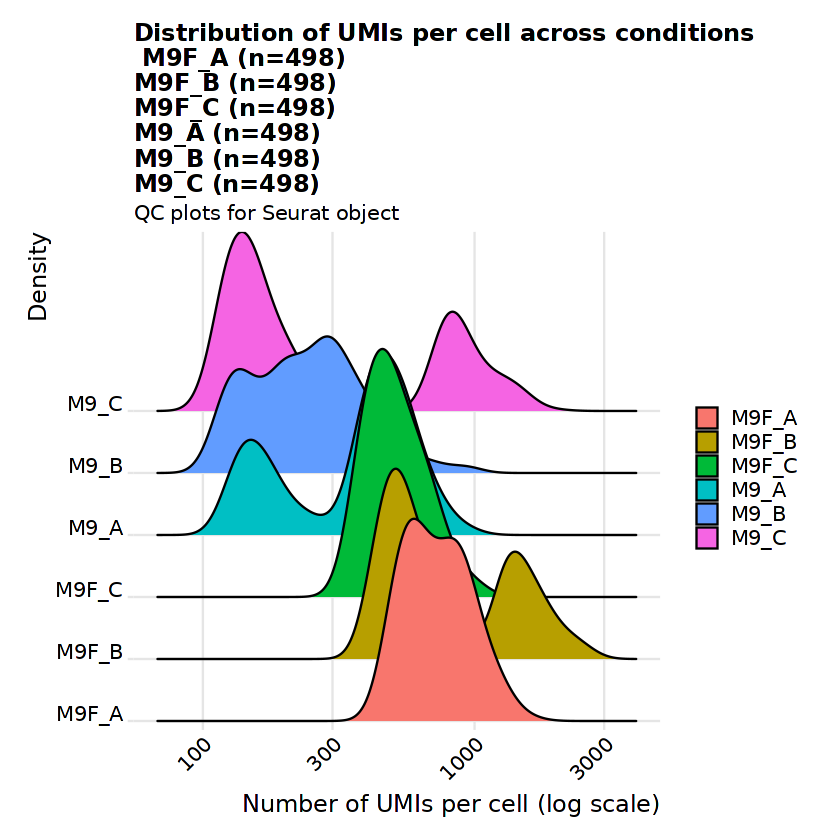

In [36]:
generate_qc_plots(
    seurat_obj = seurat_obj,
    subtitle = "QC plots for Seurat object",
    group.by = "RepBio",
    show.points = TRUE,
    color.by = "RepBio"
)

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for x is already present.
Adding another scale for x, which will replace the existing scale.


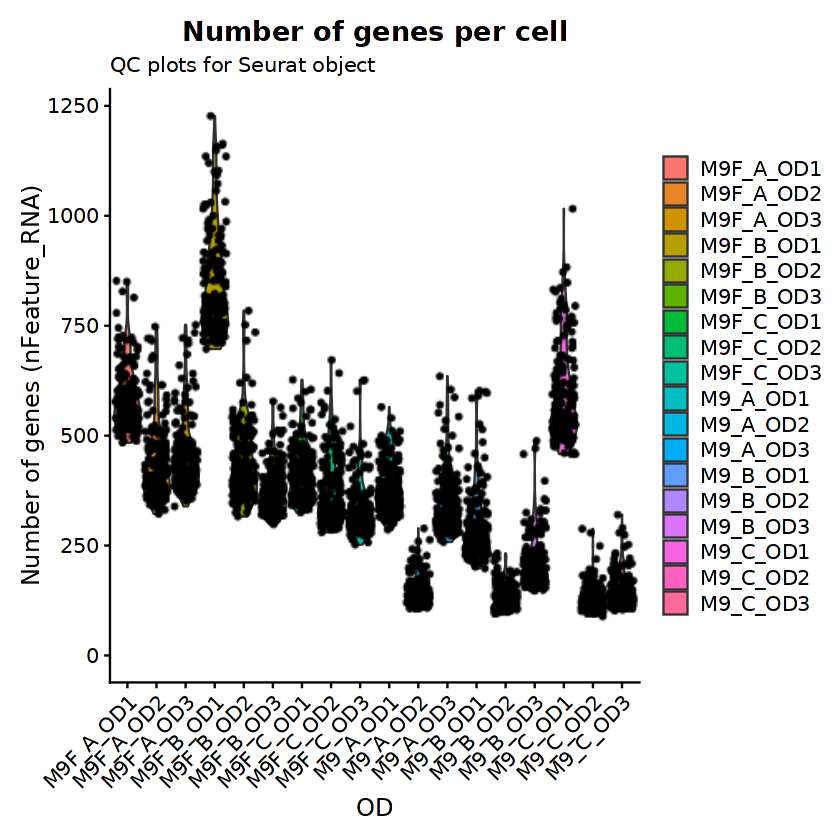

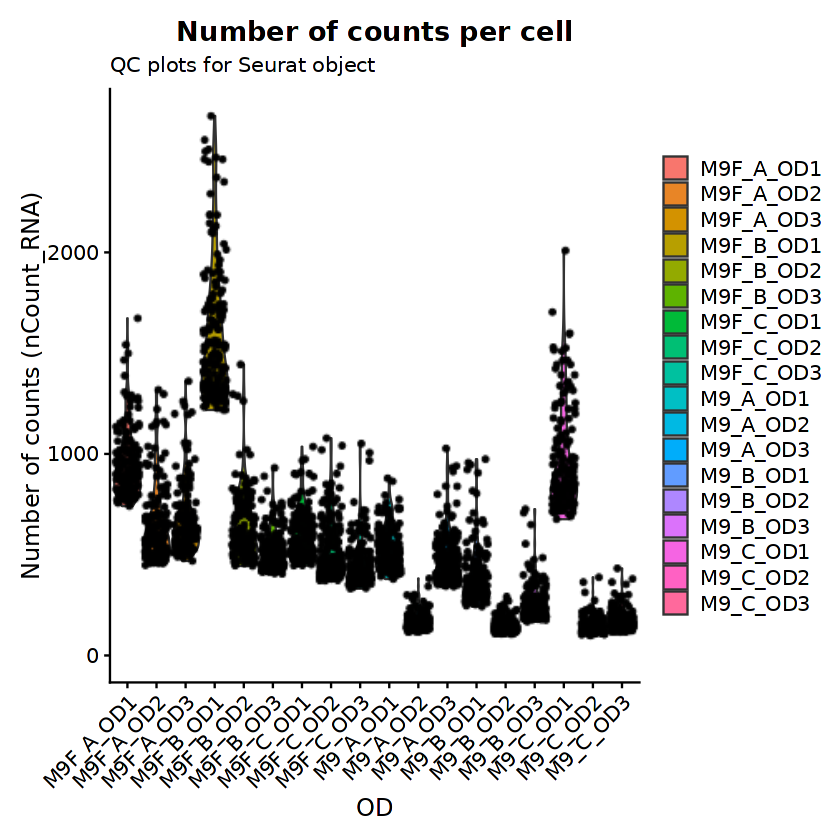

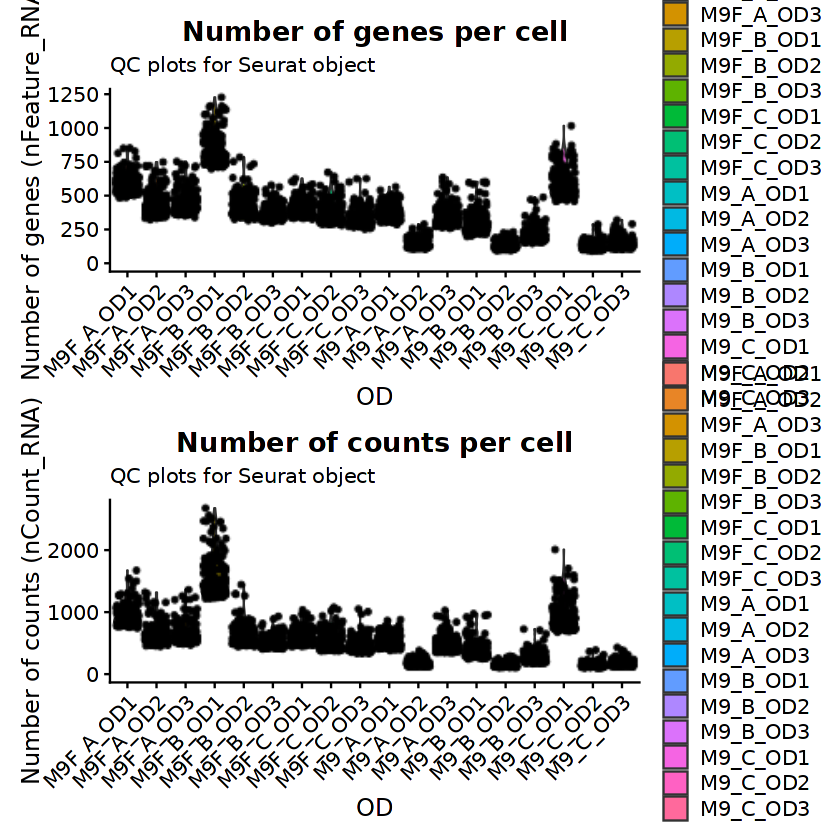

Picking joint bandwidth of 0.0294



$p1

$p2

$combined_p1_p2

$scatter_p3

$ridge_p4


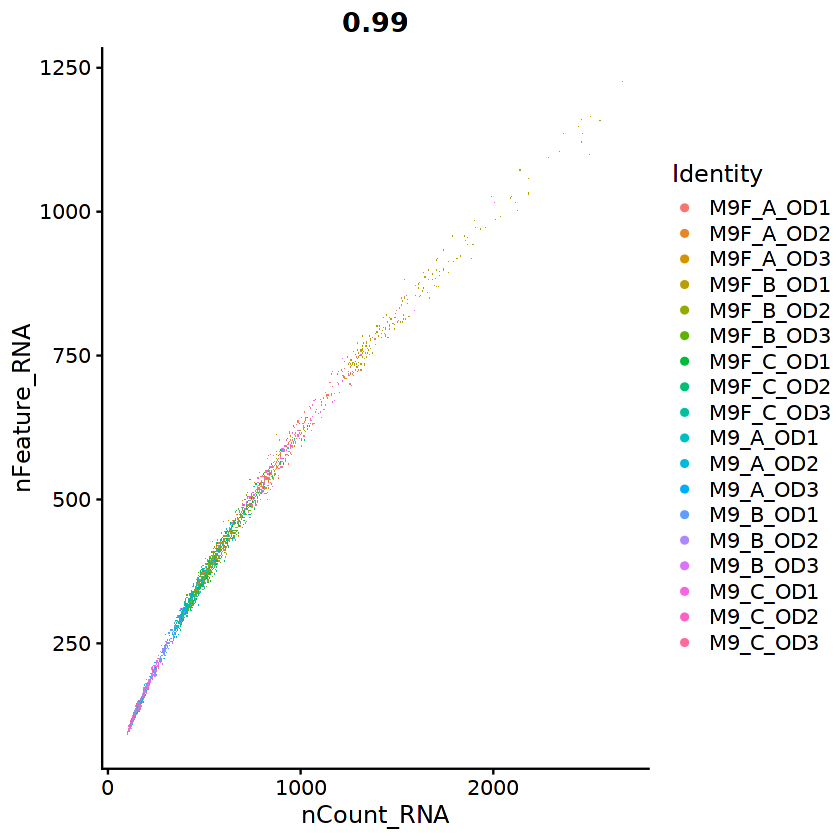

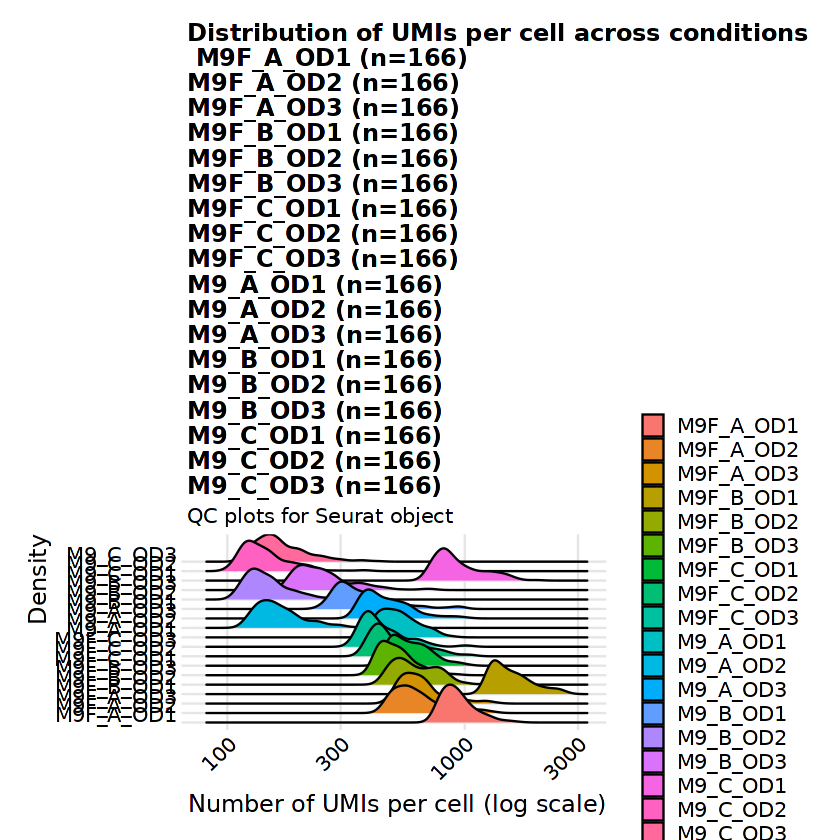

In [35]:
generate_qc_plots(
    seurat_obj = seurat_obj,
    subtitle = "QC plots for Seurat object",
    group.by = "OD",
    show.points = TRUE,
    color.by = "OD"
)

Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for y is already present.
Adding another scale for y, which will replace the existing scale.
Scale for x is already present.
Adding another scale for x, which will replace the existing scale.


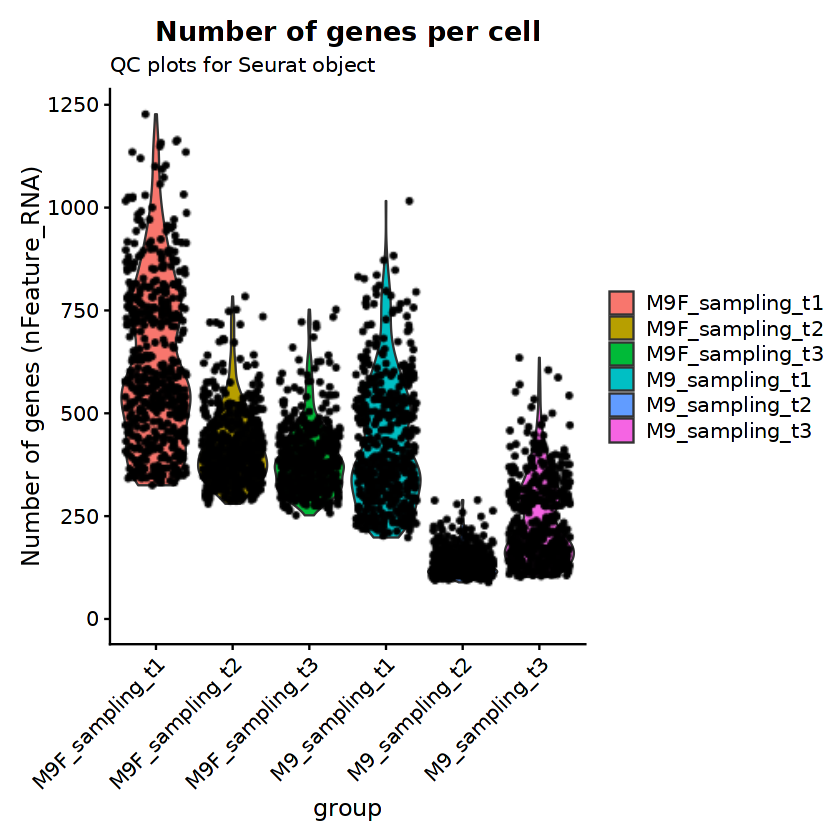

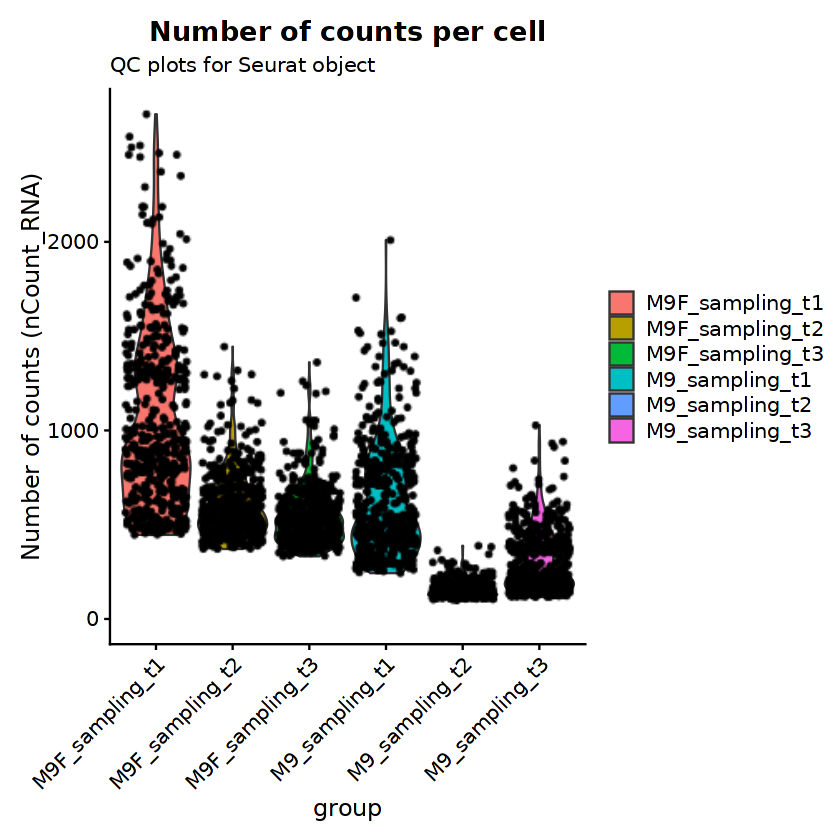

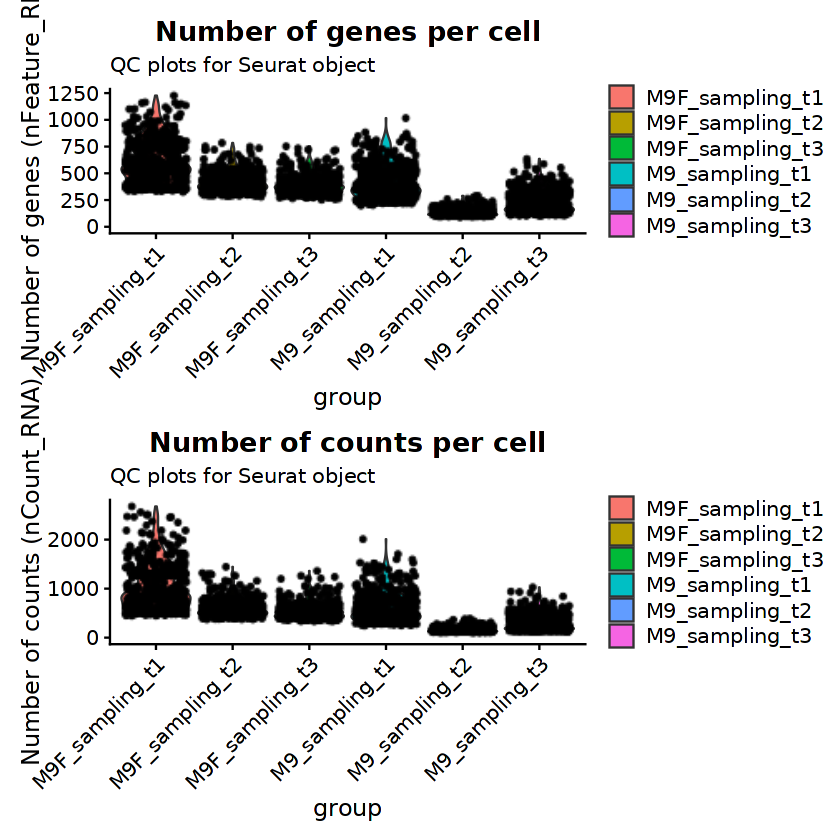

Picking joint bandwidth of 0.04



$p1

$p2

$combined_p1_p2

$scatter_p3

$ridge_p4


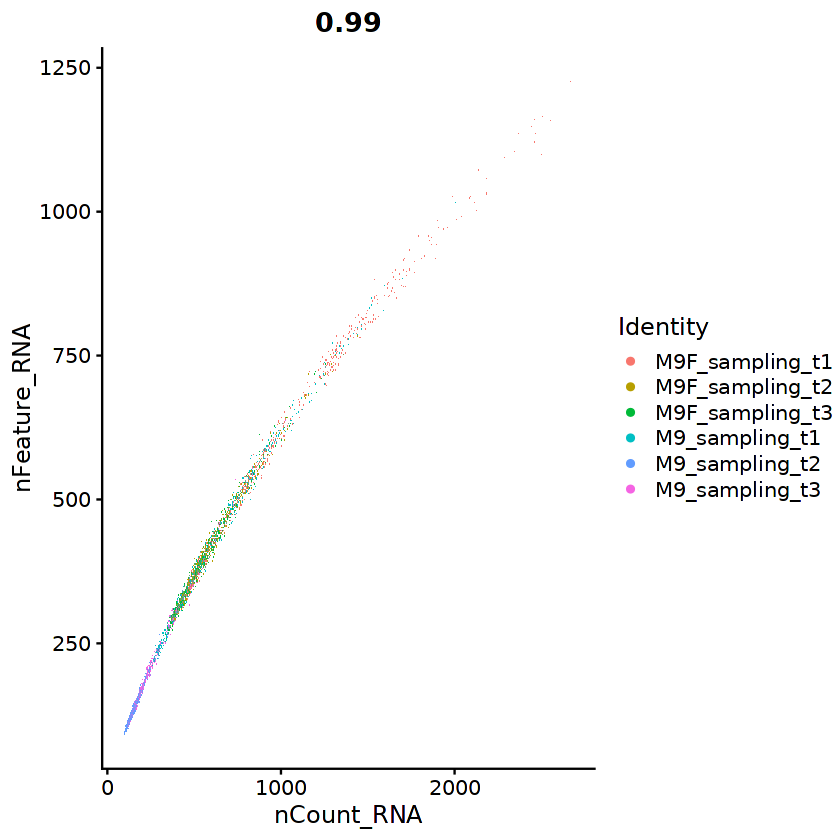

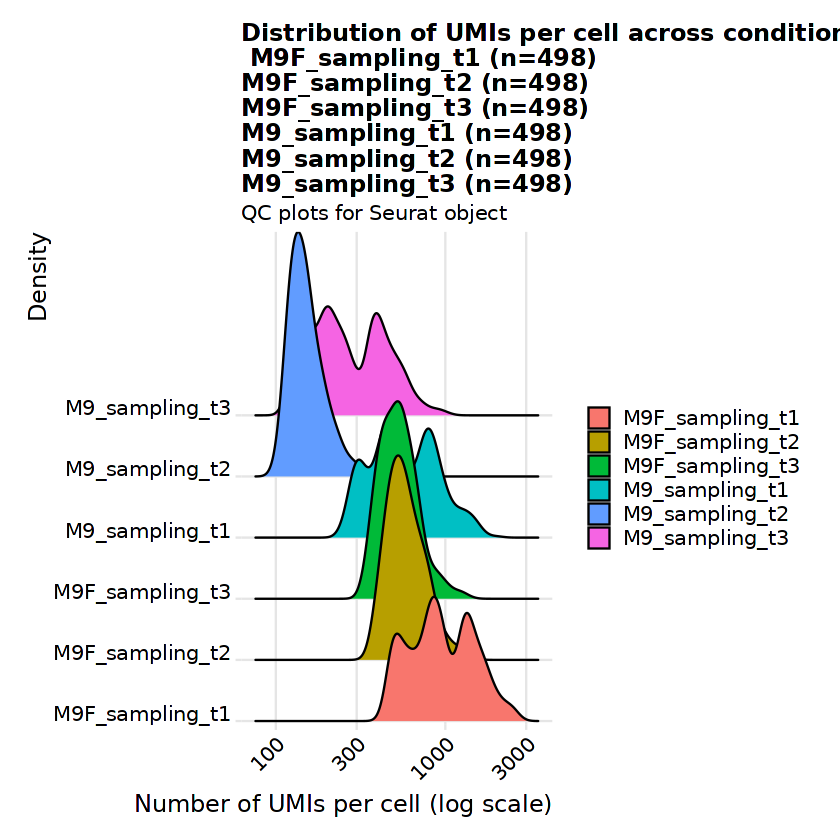

In [37]:
generate_qc_plots(
    seurat_obj = seurat_obj,
    subtitle = "QC plots for Seurat object",
    group.by = "group",
    show.points = TRUE,
    color.by = "group"
)

In [59]:

# run sctransform
seurat_obj <- SCTransform(seurat_obj, verbose = FALSE, variable.features.n = 300)

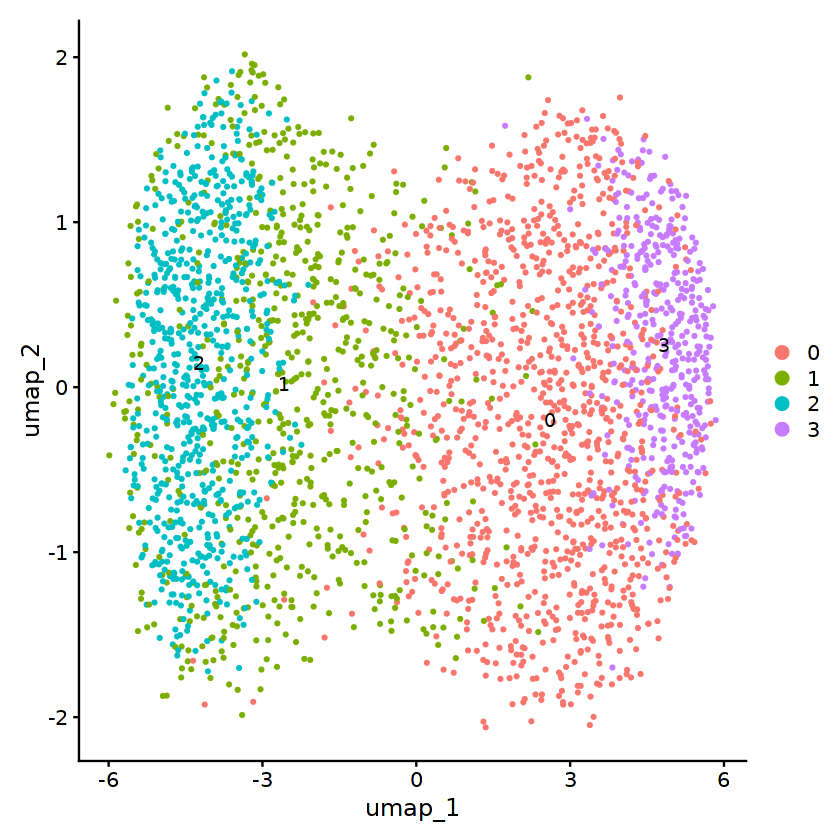

In [60]:
# These are now standard steps in the Seurat workflow for visualization and clustering
seurat_obj <- RunPCA(seurat_obj, verbose = FALSE)
seurat_obj <- RunUMAP(seurat_obj, dims = 1:30, verbose = FALSE)

seurat_obj <- FindNeighbors(seurat_obj, dims = 1:30, verbose = FALSE)
seurat_obj <- FindClusters(seurat_obj, verbose = FALSE)
DimPlot(seurat_obj, label = TRUE)

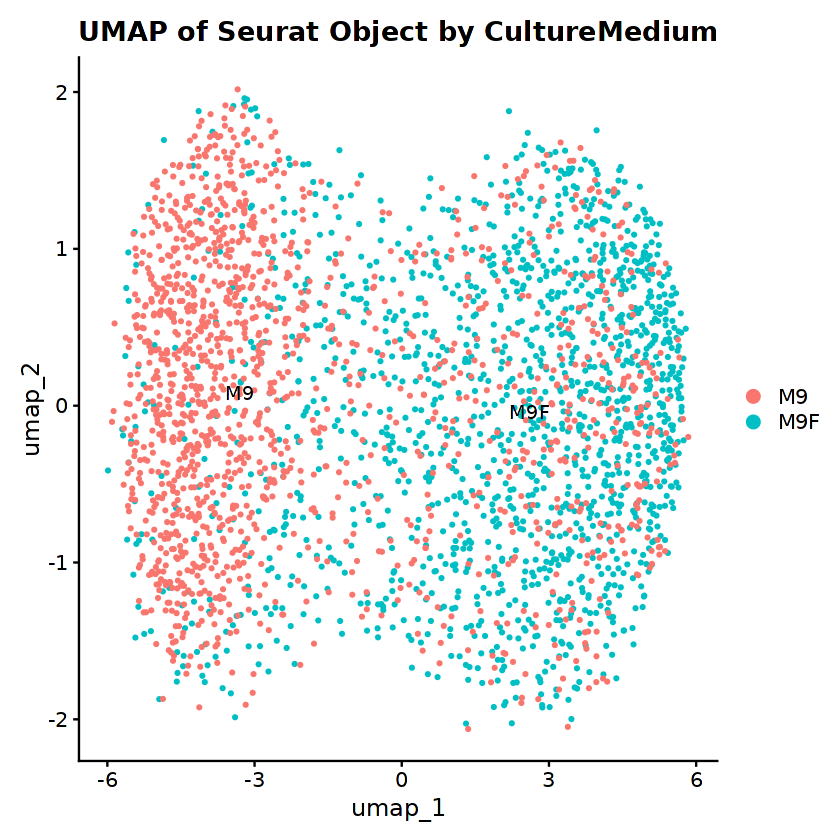

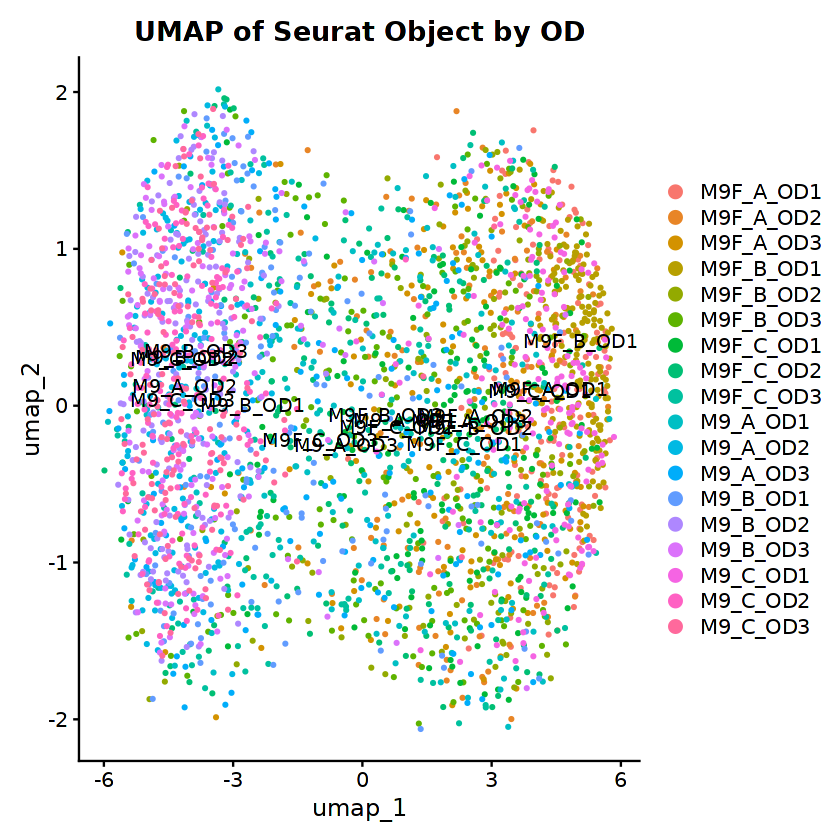

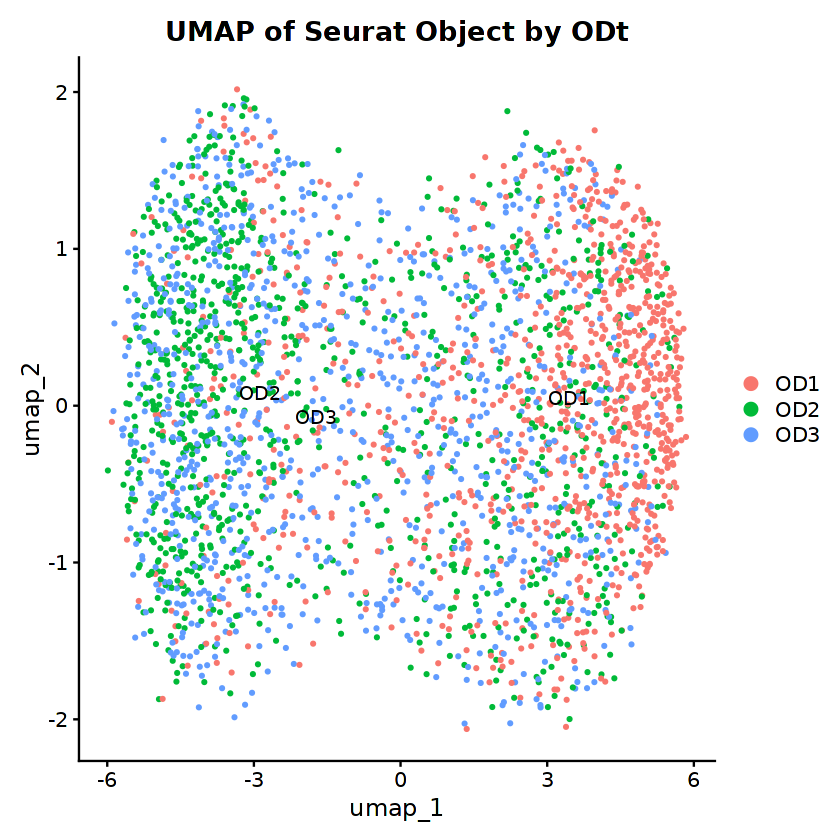

In [61]:
DimPlot(seurat_obj, group.by = "CultureMedium", label = TRUE) +
    labs(title = "UMAP of Seurat Object by CultureMedium")
DimPlot(seurat_obj, group.by = "OD", label = TRUE) +
    labs(title = "UMAP of Seurat Object by OD")
DimPlot(seurat_obj, group.by = "ODt", label = TRUE) +
    labs(title = "UMAP of Seurat Object by ODt")

In [62]:
seurat_obj

An object of class Seurat 
11000 features across 2988 samples within 2 assays 
Active assay: SCT (5500 features, 300 variable features)
 3 layers present: counts, data, scale.data
 1 other assay present: RNA
 2 dimensional reductions calculated: pca, umap

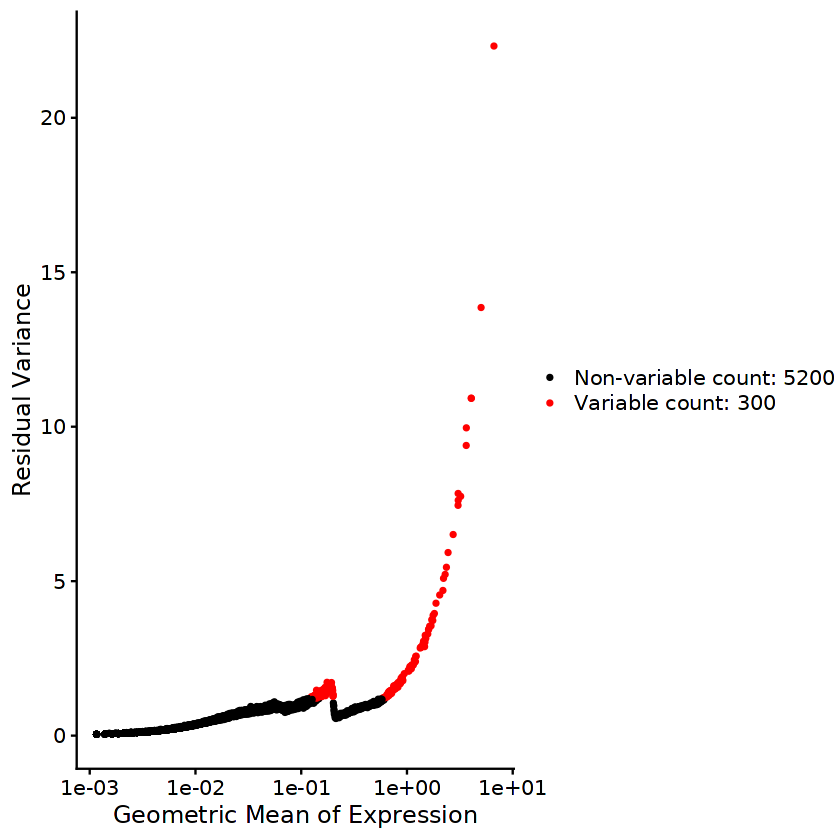

In [63]:
# Identify the 10 most highly variable genes
top10 <- head(VariableFeatures(seurat_obj), 10)

# plot variable features with and without labels
plot1 <- VariableFeaturePlot(seurat_obj)
# plot2 <- LabelPoints(plot = plot1, points = top10, repel = TRUE)
# plot1 + plot2

plot1

Sur les 5500 gene filtrés codant des mRNA 300 ont été gardé via Sctransform

In [64]:
# Examine and visualize PCA results a few different ways
print(seurat_obj[["pca"]], dims = 1:5, nfeatures = 5)

PC_ 1 
Positive:  QLH64-05400, QLH64-04320, QLH64-13710, QLH64-13705, QLH64-13720 
Negative:  QLH64-16835, QLH64-28210, aspA, grpE, QLH64-02160 
PC_ 2 
Positive:  QLH64-13710, QLH64-13720, fusA, ccoN-2, rpoC 
Negative:  QLH64-13705, QLH64-19225, QLH64-05400, QLH64-00845, aceE 
PC_ 3 
Positive:  QLH64-13705, QLH64-13710, QLH64-04320, glnA, rpoC 
Negative:  QLH64-13720, QLH64-05400, QLH64-00845, QLH64-02935, QLH64-00840 
PC_ 4 
Positive:  QLH64-13720, QLH64-13705, QLH64-00425, QLH64-00845, QLH64-02935 
Negative:  QLH64-05400, ccoN-2, QLH64-19225, QLH64-13710, QLH64-09610 
PC_ 5 
Positive:  QLH64-00425, QLH64-00845, QLH64-19225, fusA, QLH64-09610 
Negative:  QLH64-13705, QLH64-05400, QLH64-13710, QLH64-13720, ccoN-2 


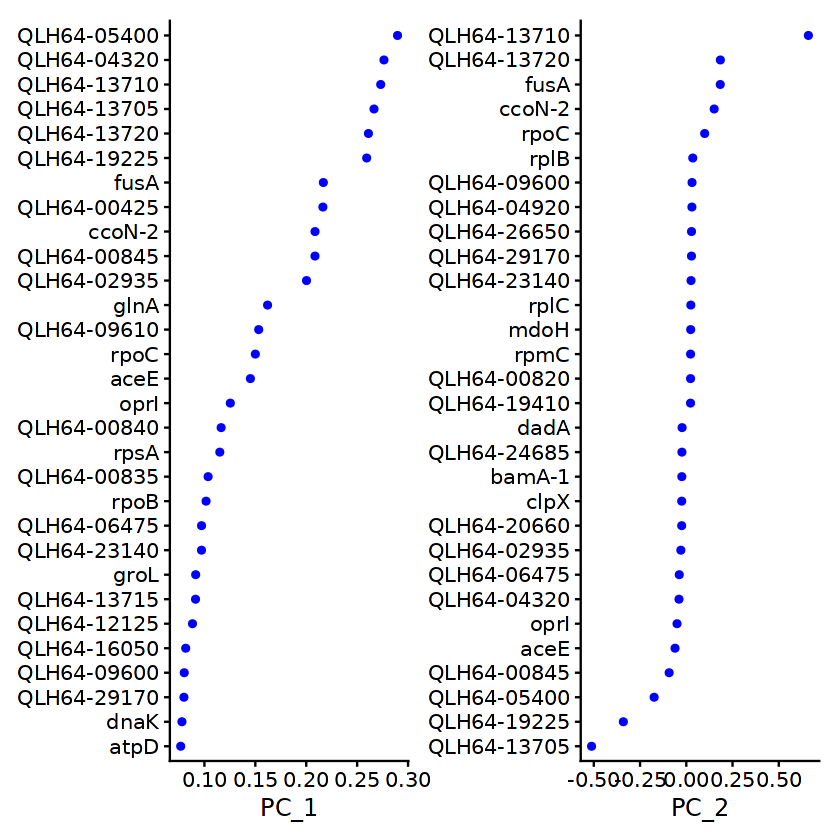

In [66]:
VizDimLoadings(seurat_obj, dims = 1:2, reduction = "pca")

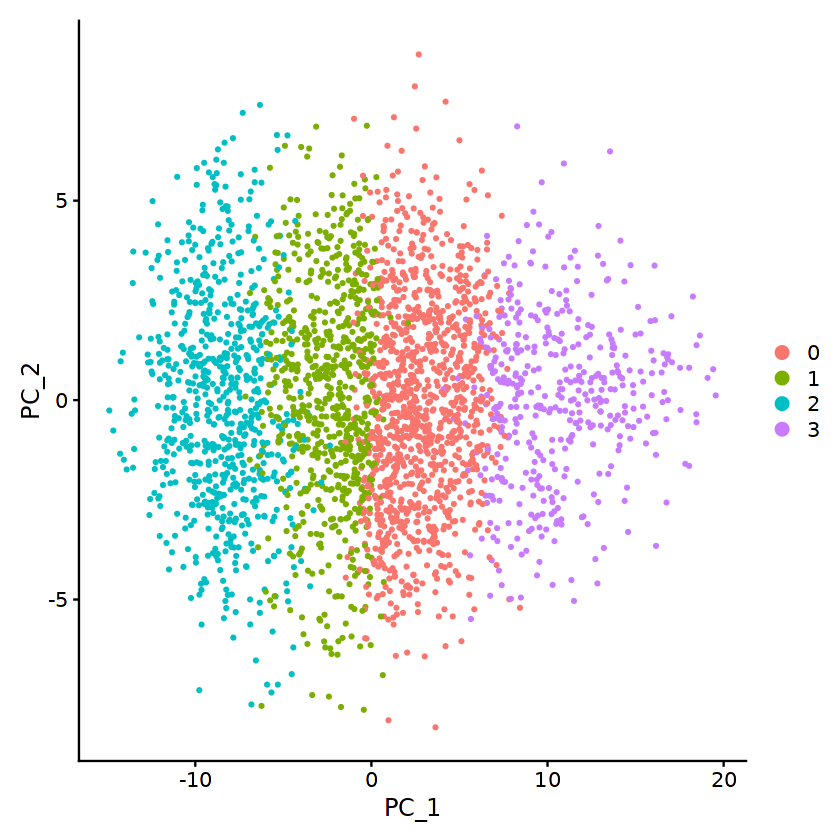

In [65]:
DimPlot(seurat_obj, reduction = "pca") 

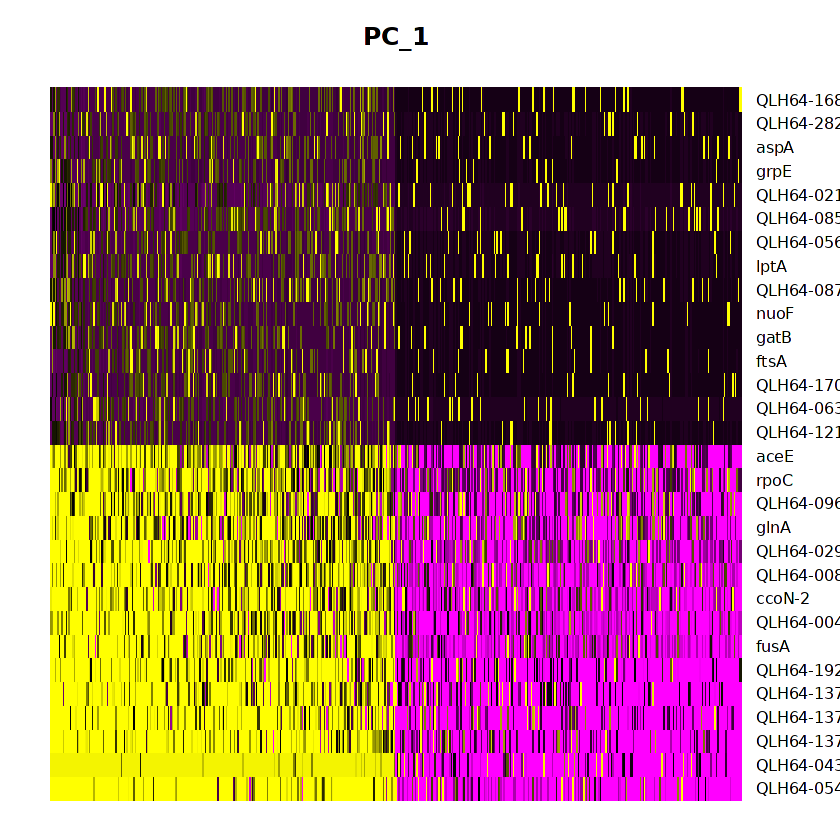

In [67]:
DimHeatmap(seurat_obj, dims = 1, cells = 500, balanced = TRUE)

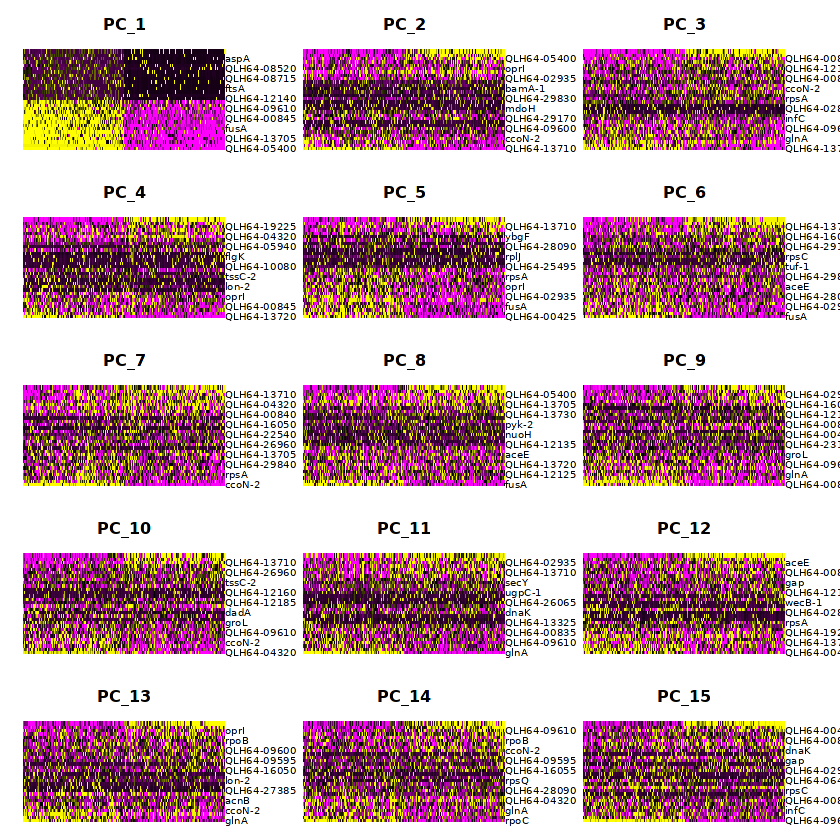

In [68]:
DimHeatmap(seurat_obj, dims = 1:15, cells = 500, balanced = TRUE)

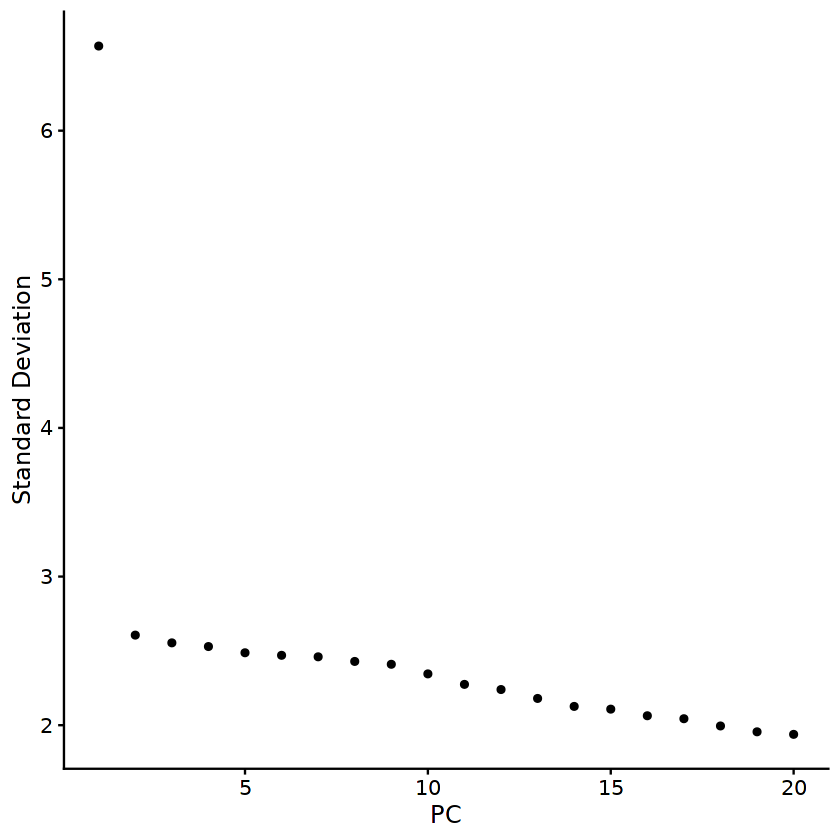

In [69]:
ElbowPlot(seurat_obj)

Warning message:
"Key 'PC_' taken, using 'pcanopc1_' instead"


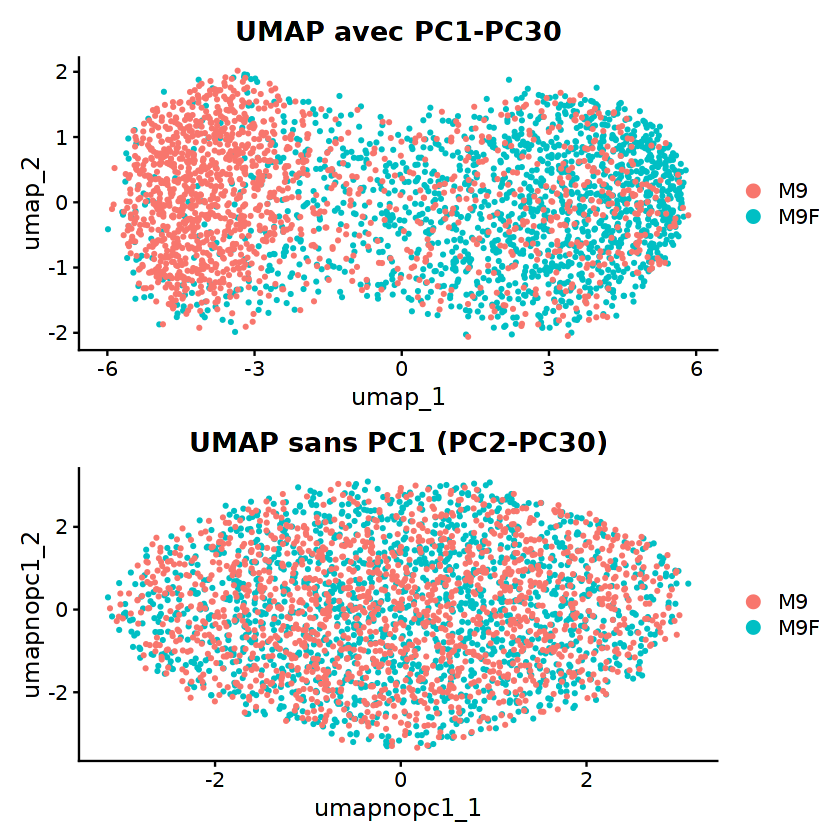

In [70]:
# Créer une copie de l'objet Seurat
seurat_obj_no_pca1 <- seurat_obj

# Supprimer PC1 des réductions PCA et recalculer UMAP
# Extraire les embeddings PCA sans PC1
pca_embeddings <- Embeddings(seurat_obj_no_pca1, "pca")
pca_embeddings_no_pc1 <- pca_embeddings[, -1]  # Supprime la première colonne (PC1)

# Créer une nouvelle réduction PCA sans PC1
seurat_obj_no_pca1[["pca_no_pc1"]] <- CreateDimReducObject(
  embeddings = pca_embeddings_no_pc1,
  key = "PC_",
  assay = DefaultAssay(seurat_obj_no_pca1)
)

# Recalculer UMAP en utilisant PC2-PC30 (au lieu de PC1-PC30)
seurat_obj_no_pca1 <- RunUMAP(seurat_obj_no_pca1, 
                               reduction = "pca_no_pc1", 
                               dims = 1:29,  # PC2-PC30 sont maintenant dims 1:29
                               verbose = FALSE,
                               reduction.name = "umap_no_pc1")

# Visualiser la différence
p1 <- DimPlot(seurat_obj, reduction = "umap", group.by = "CultureMedium") + 
  labs(title = "UMAP avec PC1-PC30")

p2 <- DimPlot(seurat_obj_no_pca1, reduction = "umap_no_pc1", group.by = "CultureMedium") + 
  labs(title = "UMAP sans PC1 (PC2-PC30)")

p1 / p2

Cellules avant filtrage: 2988 
Cellules apr<U+00E8>s filtrage: 1992 
Groupes restants:

M9F_sampling_t1 M9F_sampling_t2 M9F_sampling_t3  M9_sampling_t1  M9_sampling_t2 
            498             498             498             498               0 
 M9_sampling_t3 
              0 


Warning message:
"Different cells and/or features from existing assay SCT"


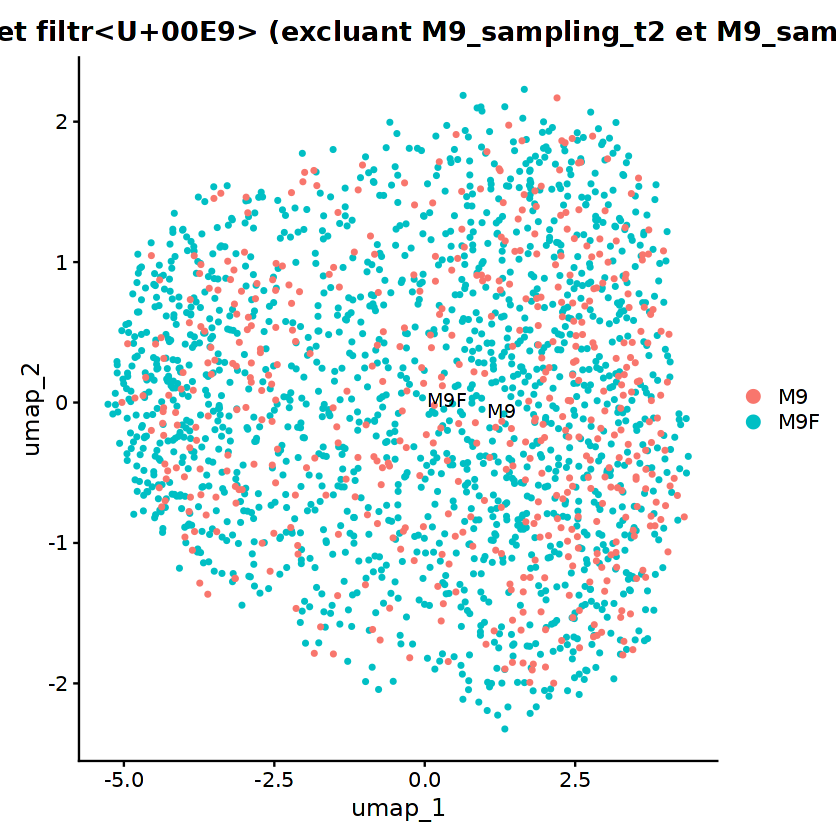

In [76]:
# Créer un objet Seurat filtré en excluant M9_sampling_t2 et M9_sampling_t3
seurat_filtered <- subset(seurat_obj, subset = group != "M9_sampling_t2" & group != "M9_sampling_t3")

# Vérifier le filtrage
cat("Cellules avant filtrage:", ncol(seurat_obj), "\n")
cat("Cellules après filtrage:", ncol(seurat_filtered), "\n")
cat("Groupes restants:\n")
print(table(seurat_filtered$group))

# Refaire l'analyse complète sur l'objet filtré
# SCTransform
seurat_filtered <- SCTransform(seurat_filtered, verbose = FALSE, variable.features.n = 300)

# PCA
seurat_filtered <- RunPCA(seurat_filtered, verbose = FALSE)

# UMAP
seurat_filtered <- RunUMAP(seurat_filtered, dims = 1:30, verbose = FALSE)

# Clustering
seurat_filtered <- FindNeighbors(seurat_filtered, dims = 1:30, verbose = FALSE)
seurat_filtered <- FindClusters(seurat_filtered, verbose = FALSE)

# Visualisation
DimPlot(seurat_filtered, group.by = "CultureMedium", label = TRUE) +
  labs(title = "UMAP - Objet filtré (excluant M9_sampling_t2 et M9_sampling_t3)")